# WICOS - Radar Hand-Gesture Classification: Model Comparison
EE4C12 Machine Learning for Electrical Engineering

Jim van IJcken (5840597), Huib Maas (5858038)

## Setup

In [2]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"     # hide TensorFlow info messages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn import svm
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay
from sklearn.model_selection import LeaveOneGroupOut, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
np.random.seed(SEED)
tf.config.experimental.enable_op_determinism()   # reproducible CNN training

FIG_DIR = Path("figures")
RES_DIR = Path("results")
FIG_DIR.mkdir(exist_ok=True)
RES_DIR.mkdir(exist_ok=True)

## Data

In [3]:
# Pre-processed dataset (run prepare_data.py first)
data = np.load("processed/wicos_dataset.npz", allow_pickle=True)

X_feat = data["X_feat"]                         # (960, 27) hand-crafted features
X_img = data["X_img"].reshape(960, -1)          # (960, 16384) flattened 128x128 spectrograms
y = data["y"]                                   # 0=wave, 1=pinch, 2=swipe, 3=click
persons = data["persons"]                       # person who performed the gesture (A-F)
gestures = list(data["gestures"])
idx_train, idx_test, cv_fold = data["idx_train"], data["idx_test"], data["cv_fold"]

print("Features:", X_feat.shape)
print("Images:  ", X_img.shape)
print("Train / test samples:", len(idx_train), "/", len(idx_test))

Features: (960, 27)
Images:   (960, 16384)
Train / test samples: 768 / 192


In [4]:
# Validation schemes
# LOSO:   train on 5 persons, validate on the 6th (generalisation to a new person)
# Random: 5 random folds in the 80% training set; best model tested once on the 20% test set
loso_folds = list(LeaveOneGroupOut().split(X_feat, y, groups=persons))
random_folds = [(idx_train[cv_fold[idx_train] != k], idx_train[cv_fold[idx_train] == k]) for k in range(5)]
SCHEMES = [("LOSO", loso_folds), ("Random", random_folds)]

print("LOSO folds:  ", len(loso_folds), "- held-out persons:", [persons[val][0] for _, val in loso_folds])
print("Random folds:", len(random_folds))

LOSO folds:   6 - held-out persons: ['A', 'B', 'C', 'D', 'E', 'F']
Random folds: 5


In [5]:
def evaluate(model, X, folds, n_jobs=-1):
    """Mean training and validation accuracy over the folds, and the validation accuracy per fold."""
    scores = cross_validate(model, X, y, cv=folds, scoring="accuracy", return_train_score=True, n_jobs=n_jobs)
    return scores["train_score"].mean(), scores["test_score"].mean(), scores["test_score"]


def best_setting(results, scheme):
    """Row of the tuning results with the highest mean validation accuracy."""
    r = results[results.scheme == scheme]
    return r.loc[r.val_acc.idxmax()]


def label(value):
    """Readable axis label for a hyperparameter value."""
    if isinstance(value, str):
        return value
    return "None" if pd.isna(value) else f"{value:g}"


def plot_tuning(results, x, hue=None, fixed=None, title="", filename=None):
    """Training (dashed) and validation (solid) accuracy versus hyperparameter x, for both schemes."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True, constrained_layout=True)
    for ax, (scheme, _) in zip(axes, SCHEMES):
        r = results[results.scheme == scheme]
        if fixed is not None:
            for key, value in fixed.items():
                r = r[r[key] == value]
        groups = r.groupby(hue, sort=False, dropna=False) if hue else [(None, r)]
        for i, (h, g) in enumerate(groups):
            xs = [label(v) for v in g[x]]
            name = f"{hue} = {label(h)}" if hue else "accuracy"
            ax.plot(xs, g.val_acc, "o-", color=f"C{i}", label=name)
            ax.plot(xs, g.train_acc, "--", color=f"C{i}", alpha=0.6)
        ax.set_title(f"{title} ({scheme})")
        ax.set_xlabel(x)
        ax.set_ylim(0.2, 1.02)
        ax.grid(alpha=0.3)
    axes[0].set_ylabel("Accuracy (solid: validation, dashed: training)")
    axes[1].legend(fontsize=8)
    if filename:
        fig.savefig(FIG_DIR / filename, bbox_inches="tight")
    plt.show()


def final_evaluation(name, model_loso, model_random, X, best_loso, best_random, n_jobs=-1):
    """LOSO predictions of the best LOSO model; test-set score of the best random-split model."""
    loso_pred = cross_val_predict(model_loso, X, y, cv=loso_folds, n_jobs=n_jobs)
    model_random.fit(X[idx_train], y[idx_train])
    test_pred = model_random.predict(X[idx_test])

    result = {
        "model": name,
        "LOSO accuracy": best_loso.val_acc,
        "LOSO std": np.std(best_loso.fold_acc, ddof=1),
        "LOSO macro-F1": f1_score(y, loso_pred, average="macro"),
        "Random CV accuracy": best_random.val_acc,
        "Test accuracy": accuracy_score(y[idx_test], test_pred),
        "Test macro-F1": f1_score(y[idx_test], test_pred, average="macro"),
        "person_acc": best_loso.fold_acc,
        "loso_pred": loso_pred,
    }
    print(f"{name}: LOSO accuracy {result['LOSO accuracy']:.3f} ± {result['LOSO std']:.3f} | "
          f"test accuracy (random split) {result['Test accuracy']:.3f}")
    return result


summary = []      # one result per model

## Logistic regression

In [6]:
# Standardised features -> multinomial logistic regression (L2 regularisation, C = inverse strength)
def build_lr(C):
    return Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(C=C, max_iter=10000)),
    ])


lr_rows = []
for C in [0.001, 0.01, 0.1, 1, 10, 100, 1000]:
    for scheme, folds in SCHEMES:
        train_acc, val_acc, fold_acc = evaluate(build_lr(C), X_feat, folds)
        lr_rows.append({"scheme": scheme, "C": C, "train_acc": train_acc, "val_acc": val_acc, "fold_acc": fold_acc})
lr_results = pd.DataFrame(lr_rows)

lr_best_loso = best_setting(lr_results, "LOSO")
lr_best_random = best_setting(lr_results, "Random")
print(f"Best C (LOSO):   {lr_best_loso.C}   validation accuracy {lr_best_loso.val_acc:.3f}")
print(f"Best C (Random): {lr_best_random.C}   validation accuracy {lr_best_random.val_acc:.3f}")

Best C (LOSO):   0.1   validation accuracy 0.721
Best C (Random): 1.0   validation accuracy 0.884


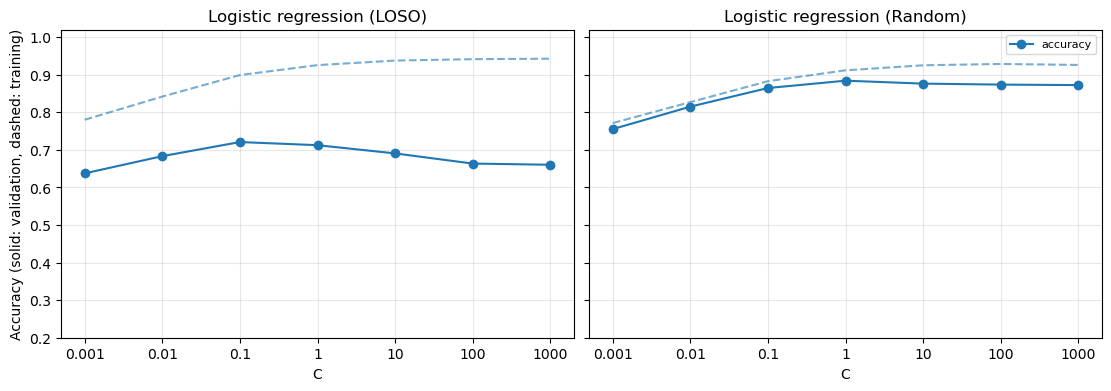

In [7]:
plot_tuning(lr_results, x="C", title="Logistic regression", filename="allmodels_lr_tuning.pdf")

In [8]:
summary.append(final_evaluation("LR", build_lr(lr_best_loso.C), build_lr(lr_best_random.C), X_feat,
                                lr_best_loso, lr_best_random))

LR: LOSO accuracy 0.721 ± 0.141 | test accuracy (random split) 0.901


## SVM (features)

In [14]:
# Standardised features -> soft-margin SVM; kernel sets the shape of the decision boundary
# Iteration limit: a linear SVM on some folds never converges (all other fits need < 2e6 iterations)
MAX_ITER = 100000


def build_svm(kernel, C):
    return Pipeline([
        ("scaler", StandardScaler()),
        ("clf", svm.SVC(kernel=kernel, C=C, max_iter=MAX_ITER)),
    ])


svm_rows = []
for kernel in ["linear", "rbf", "poly"]:
    for C in [0.1, 1, 10, 100]:
        for scheme, folds in SCHEMES:
            train_acc, val_acc, fold_acc = evaluate(build_svm(kernel, C), X_feat, folds)
            svm_rows.append({"scheme": scheme, "kernel": kernel, "C": C,
                             "train_acc": train_acc, "val_acc": val_acc, "fold_acc": fold_acc})
svm_results = pd.DataFrame(svm_rows)

svm_best_loso = best_setting(svm_results, "LOSO")
svm_best_random = best_setting(svm_results, "Random")
print(f"Best (LOSO):   kernel {svm_best_loso.kernel}, C {svm_best_loso.C}   validation accuracy {svm_best_loso.val_acc:.3f}")
print(f"Best (Random): kernel {svm_best_random.kernel}, C {svm_best_random.C}   validation accuracy {svm_best_random.val_acc:.3f}")

Best (LOSO):   kernel linear, C 0.1   validation accuracy 0.715
Best (Random): kernel rbf, C 10.0   validation accuracy 0.943


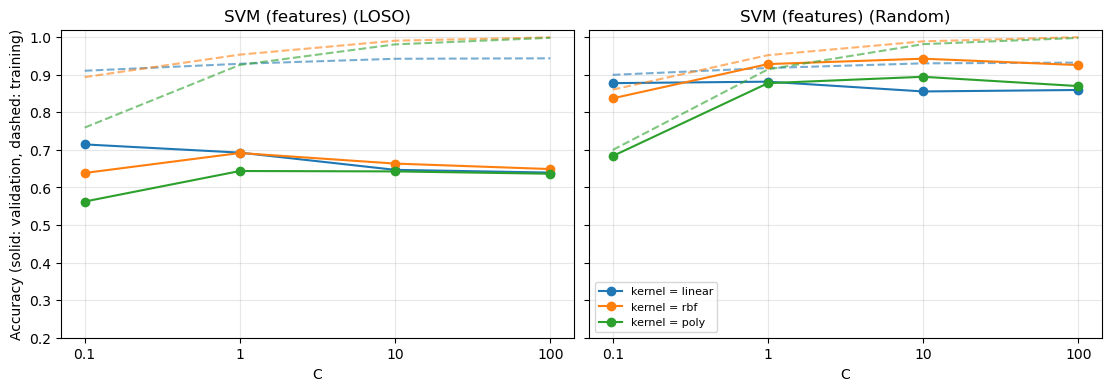

In [15]:
plot_tuning(svm_results, x="C", hue="kernel", title="SVM (features)", filename="allmodels_svm_features_tuning.pdf")

In [16]:
summary.append(final_evaluation("SVM (features)",
                                build_svm(svm_best_loso.kernel, svm_best_loso.C),
                                build_svm(svm_best_random.kernel, svm_best_random.C),
                                X_feat, svm_best_loso, svm_best_random))

SVM (features): LOSO accuracy 0.715 ± 0.159 | test accuracy (random split) 0.917


## SVM + PCA (images)

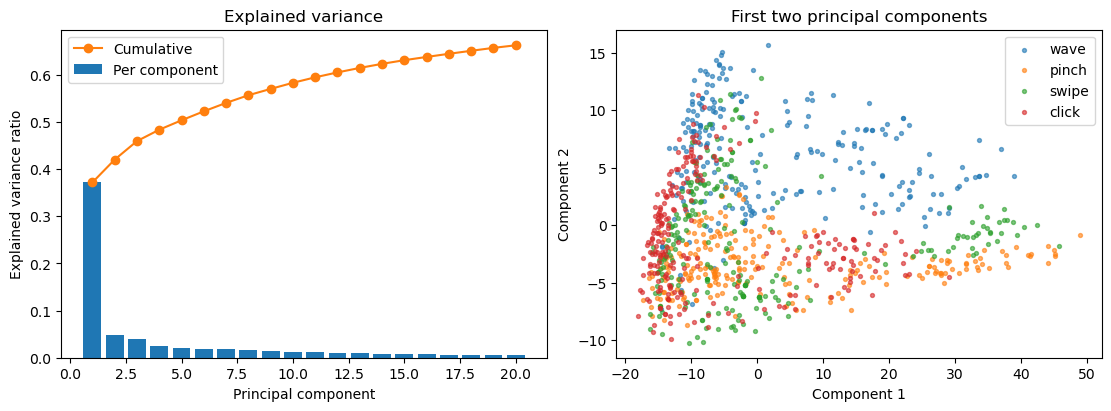

In [17]:
# PCA of all images (visualisation only; in the models PCA is fitted on the training folds)
pca = PCA(n_components=100, svd_solver="randomized", random_state=SEED)
X_pca = pca.fit_transform(X_img)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
axes[0].bar(np.arange(1, 21), pca.explained_variance_ratio_[:20], label="Per component")
axes[0].plot(np.arange(1, 21), np.cumsum(pca.explained_variance_ratio_[:20]), "o-", color="tab:orange", label="Cumulative")
axes[0].set_xlabel("Principal component")
axes[0].set_ylabel("Explained variance ratio")
axes[0].set_title("Explained variance")
axes[0].legend()
for j, g in enumerate(gestures):
    axes[1].scatter(X_pca[y == j, 0], X_pca[y == j, 1], s=8, alpha=0.6, label=g)
axes[1].set_xlabel("Component 1")
axes[1].set_ylabel("Component 2")
axes[1].set_title("First two principal components")
axes[1].legend()
fig.savefig(FIG_DIR / "allmodels_pca_images.pdf", bbox_inches="tight")
plt.show()

In [18]:
# 16384 pixels vs 960 samples: PCA (whitened) reduces the images before the SVM
def build_svm_pca(n_components, kernel, C):
    return Pipeline([
        ("pca", PCA(n_components=n_components, whiten=True, svd_solver="randomized", random_state=SEED)),
        ("clf", svm.SVC(kernel=kernel, C=C, max_iter=MAX_ITER)),
    ])


pca_rows = []
for n_components in [20, 50, 100]:
    for kernel in ["linear", "rbf", "poly"]:
        for C in [0.1, 1, 10, 100]:
            for scheme, folds in SCHEMES:
                train_acc, val_acc, fold_acc = evaluate(build_svm_pca(n_components, kernel, C), X_img, folds)
                pca_rows.append({"scheme": scheme, "n_components": n_components, "kernel": kernel, "C": C,
                                 "train_acc": train_acc, "val_acc": val_acc, "fold_acc": fold_acc})
pca_results = pd.DataFrame(pca_rows)

pca_best_loso = best_setting(pca_results, "LOSO")
pca_best_random = best_setting(pca_results, "Random")
for scheme, b in [("LOSO", pca_best_loso), ("Random", pca_best_random)]:
    print(f"Best ({scheme}): {b.n_components} components, kernel {b.kernel}, C {b.C}   validation accuracy {b.val_acc:.3f}")

Best (LOSO): 20 components, kernel rbf, C 10.0   validation accuracy 0.644
Best (Random): 20 components, kernel rbf, C 10.0   validation accuracy 0.961


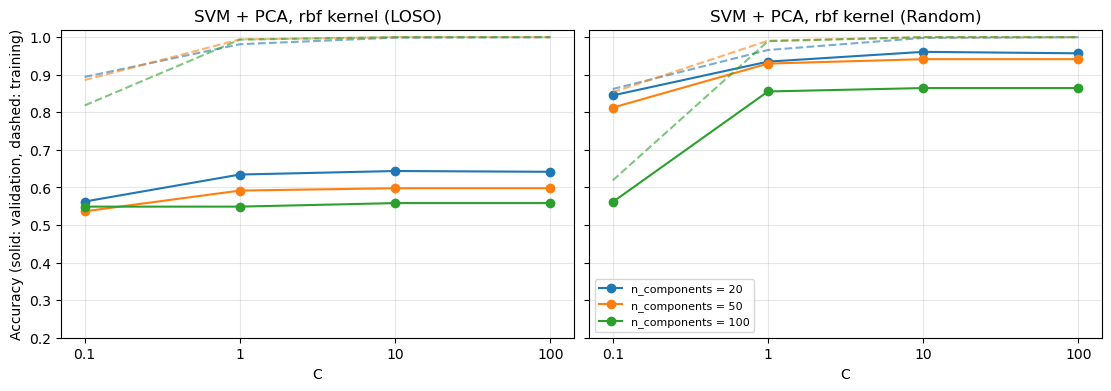

In [19]:
plot_tuning(pca_results, x="C", hue="n_components", fixed={"kernel": pca_best_loso.kernel},
            title=f"SVM + PCA, {pca_best_loso.kernel} kernel", filename="allmodels_svm_pca_tuning.pdf")

In [20]:
summary.append(final_evaluation("SVM + PCA (images)",
                                build_svm_pca(pca_best_loso.n_components, pca_best_loso.kernel, pca_best_loso.C),
                                build_svm_pca(pca_best_random.n_components, pca_best_random.kernel, pca_best_random.C),
                                X_img, pca_best_loso, pca_best_random))

SVM + PCA (images): LOSO accuracy 0.644 ± 0.171 | test accuracy (random split) 0.969


## Random forest

In [21]:
# Bagged decision trees with majority vote; no scaling needed. max_depth=None: fully grown trees
def build_rf(n_estimators, max_depth):
    return RandomForestClassifier(n_estimators=n_estimators, max_depth=max_depth, random_state=SEED)


def depth(value):
    # max_depth=None is stored as NaN in the results table
    return None if pd.isna(value) else int(value)


rf_rows = []
for n_estimators in [50, 100, 300]:
    for max_depth in [3, 5, 10, None]:
        for scheme, folds in SCHEMES:
            train_acc, val_acc, fold_acc = evaluate(build_rf(n_estimators, max_depth), X_feat, folds)
            rf_rows.append({"scheme": scheme, "n_estimators": n_estimators, "max_depth": max_depth,
                            "train_acc": train_acc, "val_acc": val_acc, "fold_acc": fold_acc})
rf_results = pd.DataFrame(rf_rows)

rf_best_loso = best_setting(rf_results, "LOSO")
rf_best_random = best_setting(rf_results, "Random")
for scheme, b in [("LOSO", rf_best_loso), ("Random", rf_best_random)]:
    print(f"Best ({scheme}): {b.n_estimators} trees, max depth {depth(b.max_depth)}   validation accuracy {b.val_acc:.3f}")

Best (LOSO): 300 trees, max depth None   validation accuracy 0.739
Best (Random): 300 trees, max depth None   validation accuracy 0.928


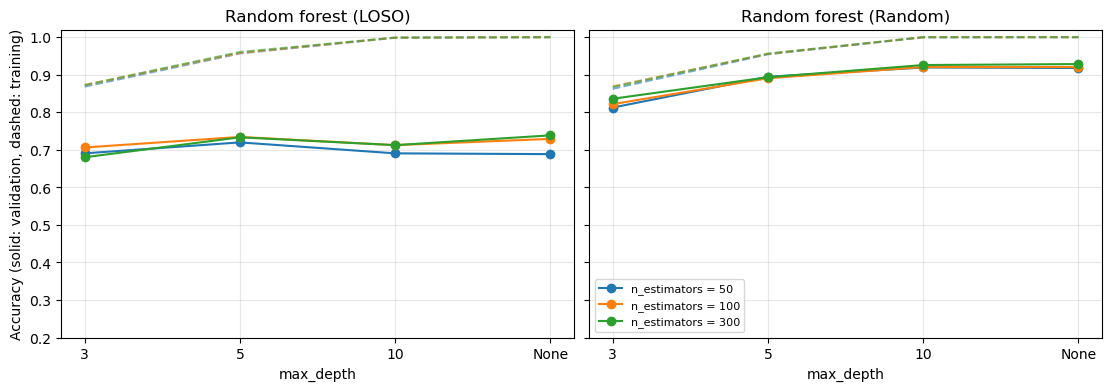

In [22]:
plot_tuning(rf_results, x="max_depth", hue="n_estimators", title="Random forest", filename="allmodels_rf_tuning.pdf")

In [23]:
summary.append(final_evaluation("RF",
                                build_rf(rf_best_loso.n_estimators, depth(rf_best_loso.max_depth)),
                                build_rf(rf_best_random.n_estimators, depth(rf_best_random.max_depth)),
                                X_feat, rf_best_loso, rf_best_random))

RF: LOSO accuracy 0.739 ± 0.081 | test accuracy (random split) 0.906


## CNN (images)

In [24]:
class CNN(ClassifierMixin, BaseEstimator):
    """4 x (3x3 conv + ReLU + 2x2 max pool) -> dropout -> softmax.

    Cross-entropy loss, mini-batch SGD (batch 32). Early stopping on the loss of 10% of the
    training data (patience 10), so the validation fold stays unseen.
    """
    def __init__(self, learning_rate=0.03, dropout=0.5, n_filters=8, epochs=100, patience=10):
        self.learning_rate = learning_rate
        self.dropout = dropout
        self.n_filters = n_filters
        self.epochs = epochs
        self.patience = patience

    def fit(self, X, y):
        keras.utils.set_random_seed(SEED)
        X = X.reshape(-1, 128, 128, 1)
        stop_set = np.random.default_rng(SEED).random(len(y)) < 0.1      # early-stopping set
        f = self.n_filters
        self.model_ = keras.Sequential([
            keras.Input(shape=(128, 128, 1)),
            layers.Conv2D(f, 3, padding="same", activation="relu"),
            layers.MaxPooling2D(2),
            layers.Conv2D(2 * f, 3, padding="same", activation="relu"),
            layers.MaxPooling2D(2),
            layers.Conv2D(4 * f, 3, padding="same", activation="relu"),
            layers.MaxPooling2D(2),
            layers.Conv2D(4 * f, 3, padding="same", activation="relu"),
            layers.MaxPooling2D(2),
            layers.Flatten(),
            layers.Dropout(self.dropout),
            layers.Dense(4, activation="softmax"),
        ])
        self.model_.compile(optimizer=keras.optimizers.SGD(learning_rate=self.learning_rate),
                            loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=self.patience, restore_best_weights=True)
        self.history_ = self.model_.fit(X[~stop_set], y[~stop_set], validation_data=(X[stop_set], y[stop_set]),
                                        epochs=self.epochs, batch_size=32, callbacks=[early_stop], verbose=0).history
        self.classes_ = np.unique(y)
        return self

    def predict(self, X):
        return self.model_.predict(X.reshape(-1, 128, 128, 1), verbose=0).argmax(axis=1)


CNN(epochs=1).fit(X_img[:64], y[:64]).model_.summary()     # architecture and number of parameters

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 8)    │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 16)     │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         8,196 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,334 (91.15 KB)

 Trainable params: 23,332 (91.14 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

In [ ]:
# Slow: 6 settings x 11 folds. n_jobs=1 because TensorFlow already uses all CPU cores
cnn_rows = []
for learning_rate in [0.01, 0.03, 0.1]:
    for dropout in [0.25, 0.5]:
        for scheme, folds in SCHEMES:
            train_acc, val_acc, fold_acc = evaluate(CNN(learning_rate=learning_rate, dropout=dropout), X_img, folds, n_jobs=1)
            cnn_rows.append({"scheme": scheme, "learning_rate": learning_rate, "dropout": dropout,
                             "train_acc": train_acc, "val_acc": val_acc, "fold_acc": fold_acc})
            print(f"lr {learning_rate}, dropout {dropout}, {scheme}: validation accuracy {val_acc:.3f}")
cnn_results = pd.DataFrame(cnn_rows)

cnn_best_loso = best_setting(cnn_results, "LOSO")
cnn_best_random = best_setting(cnn_results, "Random")
for scheme, b in [("LOSO", cnn_best_loso), ("Random", cnn_best_random)]:
    print(f"Best ({scheme}): learning rate {b.learning_rate}, dropout {b.dropout}   validation accuracy {b.val_acc:.3f}")

In [ ]:
plot_tuning(cnn_results, x="learning_rate", hue="dropout", title="CNN", filename="allmodels_cnn_tuning.pdf")

In [ ]:
cnn_random = CNN(learning_rate=cnn_best_random.learning_rate, dropout=cnn_best_random.dropout)
summary.append(final_evaluation("CNN (images)",
                                CNN(learning_rate=cnn_best_loso.learning_rate, dropout=cnn_best_loso.dropout),
                                cnn_random, X_img, cnn_best_loso, cnn_best_random, n_jobs=1))

In [ ]:
# Loss and accuracy per epoch of the final random-split CNN
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)
for ax, metric in zip(axes, ["loss", "accuracy"]):
    ax.plot(cnn_random.history_[metric], label="Training")
    ax.plot(cnn_random.history_["val_" + metric], label="Early-stopping set")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(metric.capitalize())
    ax.set_title(f"CNN {metric}")
axes[0].legend()
fig.savefig(FIG_DIR / "allmodels_cnn_training_curve.pdf", bbox_inches="tight")
plt.show()

## Comparison

In [ ]:
# LOSO accuracy = best mean validation accuracy of the tuning loop (not nested, slightly optimistic)
comparison = pd.DataFrame(summary)
comparison.drop(columns=["person_acc", "loso_pred"]).round(3)

In [ ]:
# Random split vs LOSO per model
x = np.arange(len(comparison))
plt.figure(figsize=(9, 4))
plt.bar(x - 0.2, comparison["Test accuracy"], width=0.4, label="Random split (test set)")
plt.bar(x + 0.2, comparison["LOSO accuracy"], width=0.4, yerr=comparison["LOSO std"], capsize=4, label="LOSO (mean ± std)")
plt.axhline(0.25, color="gray", ls=":", label="Chance level")
plt.xticks(x, comparison.model)
plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.title("Random split vs leave-one-subject-out")
plt.legend(loc="lower right")
plt.savefig(FIG_DIR / "allmodels_comparison_loso_vs_random.pdf", bbox_inches="tight")
plt.show()

In [ ]:
# Accuracy per held-out person
per_person = pd.DataFrame(list(comparison.person_acc), index=comparison.model,
                          columns=[persons[val][0] for _, val in loso_folds]).T
ax = per_person.plot.bar(figsize=(10, 4), width=0.8, rot=0)
ax.axhline(0.25, color="gray", ls=":")
ax.set_ylim(0, 1)
ax.set_xlabel("Held-out person")
ax.set_ylabel("Accuracy")
ax.set_title("LOSO accuracy per person")
ax.legend(ncol=3, fontsize=8, loc="lower right")
plt.savefig(FIG_DIR / "allmodels_comparison_per_person.pdf", bbox_inches="tight")
plt.show()

In [ ]:
# Confusion matrices of the LOSO predictions, summed over the six held-out persons
fig, axes = plt.subplots(1, len(comparison), figsize=(4 * len(comparison), 4), constrained_layout=True)
for ax, (_, row) in zip(axes, comparison.iterrows()):
    ConfusionMatrixDisplay.from_predictions(y, row.loso_pred, display_labels=gestures, ax=ax, colorbar=False)
    ax.set_title(row.model)
fig.savefig(FIG_DIR / "allmodels_comparison_confusion_matrices.pdf", bbox_inches="tight")
plt.show()

In [ ]:
# Save the results
comparison.drop(columns=["person_acc", "loso_pred"]).to_csv(RES_DIR / "all_models_comparison.csv", index=False)
per_person.to_csv(RES_DIR / "all_models_per_person.csv", index_label="person")